# Parte de Candela - Outliers, Groupby, EDA y Visualizacion


In [90]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

In [91]:
URL = "https://raw.githubusercontent.com/SantinoCasado/tpi-analisis-de-datos-Grupo11-2026/main/data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv"
df = pd.read_csv(URL)
df.shape

(7043, 21)

In [92]:
# provisional para poder avanzar. Se debe borrar para main
df_clean = df.copy()
df_clean["TotalCharges"] = pd.to_numeric(df_clean["TotalCharges"], errors="coerce").fillna(0)

In [93]:
df_clean["Churn_num"] = (df_clean["Churn"] == "Yes").astype(int)
COLORES = {"No": "#2a78d6", "Yes": "#eb6834"} #azul = se queda, naranja = se va

In [94]:
print(df_clean["TotalCharges"].isna().sum())
print((df_clean["TotalCharges"] == 0).sum())
print(df_clean["Churn_num"].mean().round(3))

0
11
0.265


# Paso 1: Outliers (Tarea JIRA: GIADD-7)

In [95]:
columnas = ["tenure", "MonthlyCharges", "TotalCharges"]
for col in columnas:
    q1 = df_clean[col].quantile(0.25)
    q3 = df_clean[col].quantile(0.75)
    iqr = q3 - q1
    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr
    outliers = df_clean[(df_clean[col] < limite_inferior) | (df_clean[col] > limite_superior)]

    print(col)
    print("Q1:", round(q1, 2), "| Q3:", round(q3, 2), "| IQR:", round(iqr, 2))
    print("Limites:", round(limite_inferior, 2), "a", round(limite_superior, 2))
    print("Minimo:", df_clean[col].min(), "| Maximo:", df_clean[col].max())
    print("Cantidad de Outliers:", len(outliers))
    print("-" * 40)

tenure
Q1: 9.0 | Q3: 55.0 | IQR: 46.0
Limites: -60.0 a 124.0
Minimo: 0 | Maximo: 72
Cantidad de Outliers: 0
----------------------------------------
MonthlyCharges
Q1: 35.5 | Q3: 89.85 | IQR: 54.35
Limites: -46.02 a 171.38
Minimo: 18.25 | Maximo: 118.75
Cantidad de Outliers: 0
----------------------------------------
TotalCharges
Q1: 398.55 | Q3: 3786.6 | IQR: 3388.05
Limites: -4683.52 a 8868.67
Minimo: 0.0 | Maximo: 8684.8
Cantidad de Outliers: 0
----------------------------------------


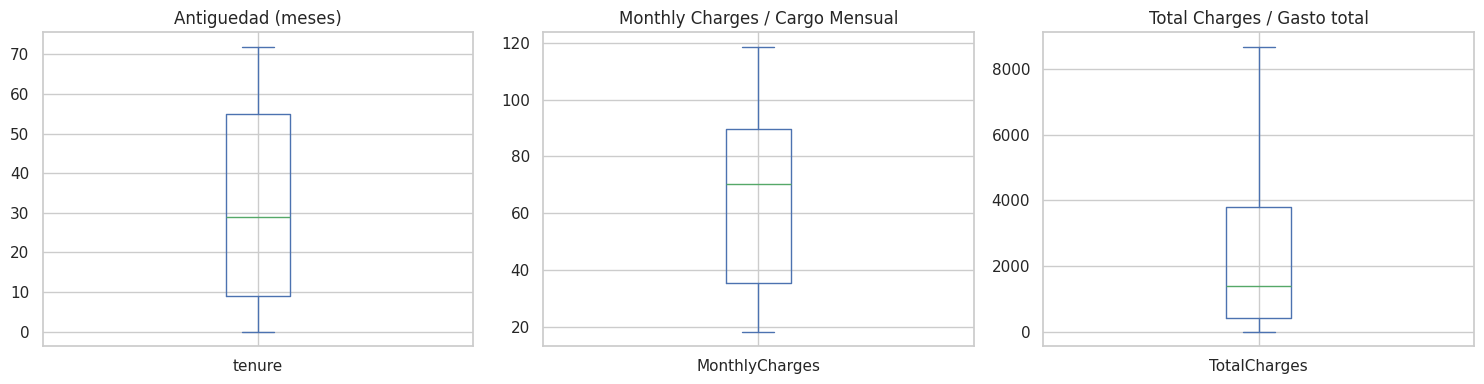

In [96]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

df_clean["tenure"].plot(kind="box", ax=axes[0])
axes[0].set_title("Antiguedad (meses)")

df_clean["MonthlyCharges"].plot(kind="box", ax=axes[1])
axes[1].set_title("Monthly Charges / Cargo Mensual")

df_clean["TotalCharges"].plot(kind="box", ax=axes[2])
axes[2].set_title("Total Charges / Gasto total")

plt.tight_layout()
plt.show()

**¿Qué muestra?** La distribucion de tenure, MonthlyCharges y TotalCharges y si hay valores fuera de los bigotes (metodo IQR)

**Dato Concreto** Ninguna de las tres variables tienen outliers. 
- En *tenure* los limtes son [-60: 124] y los datos van de 0 a 72 meses
- En *MonthlyCharges* los limites son [-46,02; 171,38] y los datos van de 18.25 a 118,75
- En *TotalCharges* los limites [-4.6383,52; 8.868,67] y los datos van de 0 a 8.684,80

**Interpretacion:** Los valores altos son los clientes reales (con mucha antiguedad o planes caros), no errores de carga

**Decision de negocio** No se elimina ningun registro; `df_clean` queda como DataFrame final para el resto del analisis

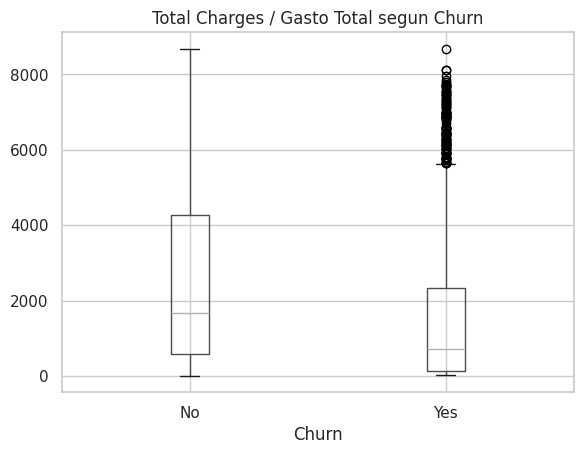

In [97]:
df_clean.boxplot(column="TotalCharges", by="Churn")
plt.title("Total Charges / Gasto Total segun Churn")
plt.suptitle("")
plt.show()

In [98]:
churn_si = df_clean[df_clean["Churn"] == "Yes"]

q1 = churn_si["TotalCharges"].quantile(0.25)
q3 = churn_si["TotalCharges"].quantile(0.75)
iqr = q3 - q1
limite_superior = q3 + 1.5 * iqr

altos = churn_si[churn_si["TotalCharges"] > limite_superior]

print("Cantidad de valores altos:", len(altos))
print("Antiguedad promedio:", round(altos["tenure"].mean(), 1 ))
print("Cargo mensual promedio", round(altos["MonthlyCharges"].mean(), 2))
print("-" * 40)
print(altos["InternetService"].value_counts())

Cantidad de valores altos: 109
Antiguedad promedio: 63.9
Cargo mensual promedio 104.15
----------------------------------------
InternetService
Fiber optic    108
DSL              1
Name: count, dtype: int64


In [99]:
cociente = df_clean["TotalCharges"] / (df_clean["tenure"] * df_clean["MonthlyCharges"])
print("Mediana del cociente", round(cociente.median(), 2))

Mediana del cociente 1.0


**¿Qué muestra?** El gasto total separado entre clientes que se quedan (No) y que se van (Yes)

**Dato Concreto** Dentro de Churn = Yes hay 109 valores altos de TotalCharges; promedian 63,9 meses de antiguedad y 104,15 de cargo mensual, y 108 de ellos tienen `Fiber Optic`. Ademas TotalCharges ≈ tenure × MonthlyCharges (mediana del cociente = 1.00)

**Interpretacion** No son errores: son clientes antiguos con planes caros que igualmente se dieron de baja

**Decision de negocio** Se conservan, por que son los clientes mas valiosos perdidos y es importante estudiarlos y analizarlos (fibra optica con cargo alto). `df_clean` queda como dataFrame final

## Paso 2: Groupby (Tarea JIRA: G1ADD-15)

In [100]:
por_contrato = df_clean.groupby("Contract").agg({"Churn_num": ["count", "sum", "mean"]})
print(por_contrato.round(3))

               Churn_num             
                   count   sum   mean
Contract                             
Month-to-month      3875  1655  0.427
One year            1473   166  0.113
Two year            1695    48  0.028


In [101]:
bajas = df_clean.groupby("Contract")["Churn_num"].sum()
print((bajas / bajas.sum() * 100).round(1))

Contract
Month-to-month    88.6
One year           8.9
Two year           2.6
Name: Churn_num, dtype: float64


**¿Qué muestra?** Cantidad de clientes, bajas y tasa de churn según el tipo de contrato

**Dato concreto**
- Month-to-Month: 3.875 clientes, 1.655 bajas -> 42.7% de churn
- One year: 1.473 clientes, 166 bajas -> 11,3% de churn
- Two year: 1.695 clientes, 48 bajas -> 2,8% de churn
- En contrato mes a mes concetra el 88,6% de todas las bajas

**Interpretacion** Cuanto mas largo es el contrato, menos clientes se van. El cliente mes a mes no tiene ningun compromiso que lo retenga

**Decision de negocio** Ofrecer algun incentivo ya sea descuento o beneficio para que los clientes mes a mes pasen a contratos de 1 o 2 años


In [102]:
por_internet = df_clean.groupby("InternetService").agg({"Churn_num": ["count", "sum", "mean"]})
print(por_internet.round(3))

                Churn_num             
                    count   sum   mean
InternetService                       
DSL                  2421   459  0.190
Fiber optic          3096  1297  0.419
No                   1526   113  0.074


**¿Qué muestra?** La cantidad de clientes, bajas y tasa de churn segun el servicio de internet

**Dato concreto**
- DSL: 2.421 clientes, 459 bajas -> 19,0% de churn
- Fiber optic: 3.096 clientes, 1.297 -> 41,9% de churn
- No/No internet: 1.526 clientes, 113 bajas -> 7.4% de churn

**Interpretacion** La fibra optica, que es el servicio mas caro, tiene mas del doble de churn que DLS. Coincide con lo visto en outliers: 108 de los 109 clientes valiosos que se fueron, tenian Fiber optic.

**Decision de negocio** Revisar el precio y la calidad del servicio de fibra optica, porque es donde se pierden mas clientes

In [103]:
por_pago = df_clean.groupby("PaymentMethod").agg({"Churn_num": ["count", "sum", "mean"]})
print(por_pago.round(3))

                          Churn_num             
                              count   sum   mean
PaymentMethod                                   
Bank transfer (automatic)      1544   258  0.167
Credit card (automatic)        1522   232  0.152
Electronic check               2365  1071  0.453
Mailed check                   1612   308  0.191


**¿Qué muestra?** La cantidad de clientes, bajas y tasa de churn segun el medio de pago

**Dato concreto**
- Electronic check: 2.365 clientes, 1.071 bajas -> 45,3% de churn
- Mailed check: 19,1%. Back transfer (automatic): 16,7%. Credit card (automatic): 15,2%

**Interpretacion** El cheque electronico casi triplica el churn de los pagos automaticos. Los pagos automaticos (transferencia o tarjeta) hacen que el cliente no tenga que decidir todos los meses si sigue pagando

**Decision de negocio** Incentivar el cambio a pago automatico, por ejemplo con un descuento por adherirse al debito coon tarjeta o banco

## Paso 3: EDA cuantitativo (Tarea JIRA: G1ADD-8)

In [104]:
columnas = ["tenure", "MonthlyCharges", "TotalCharges"]
print(df_clean[columnas].describe().round(2))

        tenure  MonthlyCharges  TotalCharges
count  7043.00         7043.00       7043.00
mean     32.37           64.76       2279.73
std      24.56           30.09       2266.79
min       0.00           18.25          0.00
25%       9.00           35.50        398.55
50%      29.00           70.35       1394.55
75%      55.00           89.85       3786.60
max      72.00          118.75       8684.80


In [105]:
for col in columnas:
    print(col)
    print("Media:", round(df_clean[col].mean(), 2))
    print("Mediana:", round(df_clean[col].median(), 2))
    print("Desvio estandar:", round(df_clean[col].std(), 2))
    print("Varianza:", round(df_clean[col].var(), 2))
    print("IQR:", round(df_clean[col].quantile(0.75) - df_clean[col].quantile(0.25), 2))
    print("Asimetria:", round(df_clean[col].skew(), 2))
    print("Curtosis:", round(df_clean[col].kurt(), 2))
    print("-" * 40)

tenure
Media: 32.37
Mediana: 29.0
Desvio estandar: 24.56
Varianza: 603.17
IQR: 46.0
Asimetria: 0.24
Curtosis: -1.39
----------------------------------------
MonthlyCharges
Media: 64.76
Mediana: 70.35
Desvio estandar: 30.09
Varianza: 905.41
IQR: 54.35
Asimetria: -0.22
Curtosis: -1.26
----------------------------------------
TotalCharges
Media: 2279.73
Mediana: 1394.55
Desvio estandar: 2266.79
Varianza: 5138357.17
IQR: 3388.05
Asimetria: 0.96
Curtosis: -0.23
----------------------------------------


In [106]:
print(df_clean["tenure"].value_counts().head(3))

tenure
1     613
72    362
2     238
Name: count, dtype: int64


**¿Qué muestra?** Medidas de tendencia central, dispersion y forma de tenure, MonthlyCharges y TotalCharges

**Dato concreto**
- Tenure: media 32,37 y mediana 29 meses; moda 1 mes (613 clientes)
- MonthlyCharges: media 64,76 y mediana 70,35; asimetria -0,22
- TotalCharges: media 2.279,73 y mediana 1.394,55; asimetria 0,96 (la mas asimetrica)

- Las tres variables tienen curtosis negativa (distribuciones planas, sin colas pesadas)

**Interpretacion** TotalCharges tiene asimetria positiva: la mayoria de los clientes gastó poco y unos pocos gastaron mucho, por eso la mediana lo representa mejor que la media. La moda de tenure en 1 mes indica que hay muchos clientes recien llegados. La curtosis negativa coincide con lo visto en el Paso 1: no hay outliers

**Decision de negocio** Usar la mediana para describir al cliente típico en gasto total, y prestar atencion a los clientes de los primeros meses, que son un grupo muy numeroso

In [107]:
cols_corr = ["tenure", "MonthlyCharges", "TotalCharges", "Churn_num"]
pearson = df_clean[cols_corr].corr()
print(pearson.round(2))

                tenure  MonthlyCharges  TotalCharges  Churn_num
tenure            1.00            0.25          0.83      -0.35
MonthlyCharges    0.25            1.00          0.65       0.19
TotalCharges      0.83            0.65          1.00      -0.20
Churn_num        -0.35            0.19         -0.20       1.00


In [108]:
spearman = df_clean[cols_corr].corr(method="spearman")
print(spearman.round(2))

                tenure  MonthlyCharges  TotalCharges  Churn_num
tenure            1.00            0.28          0.89      -0.37
MonthlyCharges    0.28            1.00          0.64       0.18
TotalCharges      0.89            0.64          1.00      -0.23
Churn_num        -0.37            0.18         -0.23       1.00


**¿Qué muestra?** La correlacion de Pearson y de Spearman entre tenure, MonthlyCharges, TotalCharges y Churn

**Dato Concreto** (Pearson P | Spearman S)
- Tenure - TotalCharges: P: 0,83, S: 0,89 -> Relacion fuerte y positiva
- MonthlyCharges - TotalCharges: P: 0,65, S: 0,64
- Tenure - MonthlyCharges: P: 0,25, S: 0,28 -> Relacion debil
- Tenure - Churn: P: -0,35, S: -0,37 -> a mas antiguedad menos bajas
- MonthlyCharges - Churn: P: 0,19, S: 0,18 -> a mayor cargo, algo mas de bajas 

**Interpretacion** La antiguedad es la variable numerica mas relacionada con el churn: los clientes nuevos se van mucho mas. TotalCharges esta muy correlacionada con tenure porque se calcula a partir de ella (meses × cargo mensual). Pearson y Spearman dan resultados parecidos, asi que las conclusiones son solidas

**Decision de negocio** Concentrar las acciones de retencion en los primeros meses del cliente, que es cuando mas riesgo hay de que se vaya

## Paso 4: Visualizacion (Tarea JIRA: G1ADD-17)

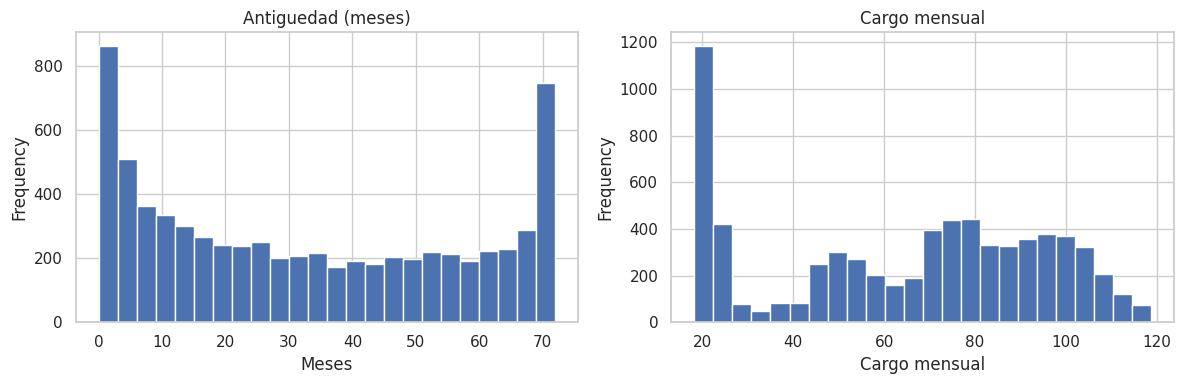

In [109]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

df_clean["tenure"].plot(kind="hist", bins=24, ax=axes[0])
axes[0].set_title("Antiguedad (meses)")
axes[0].set_xlabel("Meses")

df_clean["MonthlyCharges"].plot(kind="hist", bins=24, ax=axes[1])
axes[1].set_title("Cargo mensual")
axes[1].set_xlabel("Cargo mensual")

plt.tight_layout()
plt.show()

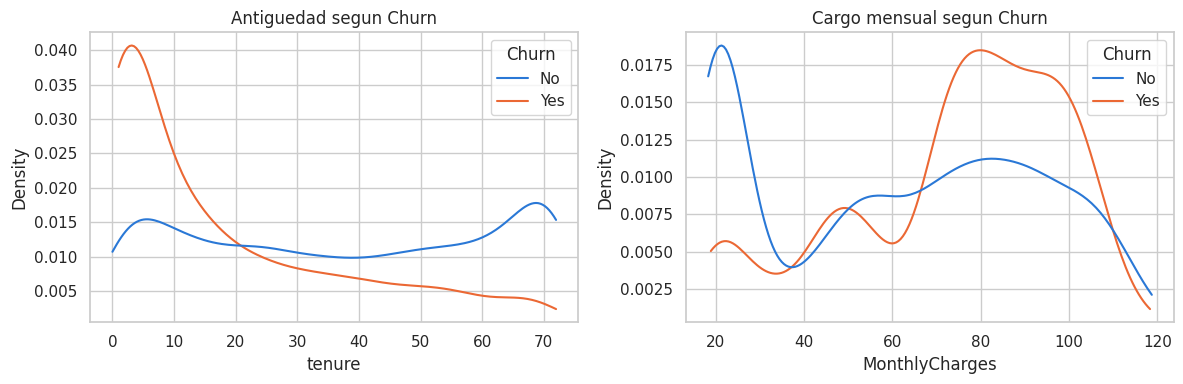

In [110]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.kdeplot(data=df_clean, x="tenure", hue="Churn", palette=COLORES, common_norm=False, cut=0, ax=axes[0])
axes[0].set_title("Antiguedad segun Churn")

sns.kdeplot(data=df_clean, x="MonthlyCharges", hue="Churn", palette=COLORES, common_norm=False, cut=0, ax=axes[1])
axes[1].set_title("Cargo mensual segun Churn")

plt.tight_layout()

plt.show()


In [111]:
nuevos = df_clean[df_clean["tenure"] <= 12]
antiguos = df_clean[df_clean["tenure"] > 48]
print("Churn con 12 meses o menos:", round(nuevos["Churn_num"].mean() * 100, 1), "%")
print("Churn con más de 48 meses:", round(antiguos["Churn_num"].mean() * 100, 1), "%")
print("-" * 40)

baratos = df_clean[df_clean["MonthlyCharges"] < 25]
print("Clientes que pagan menos de 25:", round(len(baratos) / len(df_clean) * 100, 1), "%")

hasta_30 = df_clean[df_clean["MonthlyCharges"] <= 30]
entre_70_90 = df_clean[(df_clean["MonthlyCharges"] > 70) & (df_clean["MonthlyCharges"] <= 90)]
print("Churn con cargo hasta 30:", round(hasta_30["Churn_num"].mean() * 100, 1), "%")
print("Churn con cargo entre 70 y 90:", round(entre_70_90["Churn_num"].mean() * 100, 1), "%")

Churn con 12 meses o menos: 47.4 %
Churn con más de 48 meses: 9.5 %
----------------------------------------
Clientes que pagan menos de 25: 19.7 %
Churn con cargo hasta 30: 9.8 %
Churn con cargo entre 70 y 90: 37.8 %


**¿Qué muestra?** La distribución de tenure y MonthlyCharges: primero en general (histogramas) y después separada entre clientes que se quedan y que se van (KDE).

**Dato concreto:**
- Tenure: el churn es de 47,4% entre los clientes con 12 meses o menos, y de solo 9,5% entre los que llevan más de 48 meses.
- MonthlyCharges: el 19,7% de los clientes paga menos de 25. El churn es de 9,8% con cargos de hasta 30, y de 37,8% con cargos entre 70 y 90.

**Interpretación:** El primer año es el momento de mayor riesgo: casi la mitad de los clientes nuevos se va. Los que pagan poco (servicios básicos, sin internet) casi no se van; en cambio, los cargos medios-altos (donde está la fibra óptica) concentran muchas bajas.

**Decisión de negocio:** Crear un programa de bienvenida y seguimiento para los clientes en su primer año, y revisar la relación precio/servicio de los planes de 70 a 90.


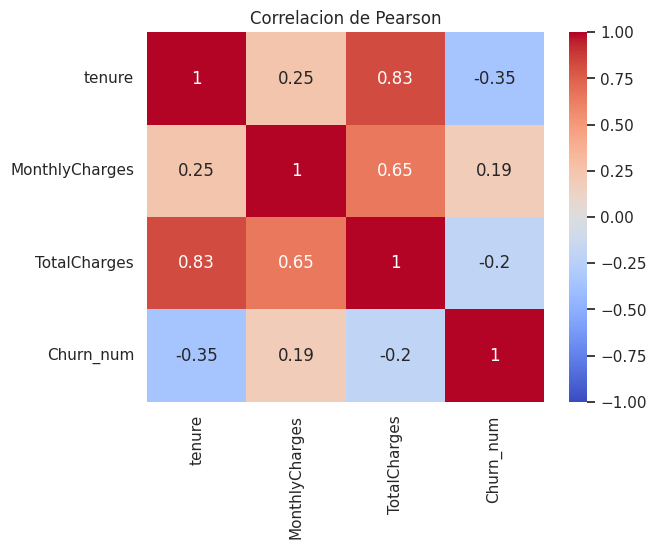

In [112]:
sns.heatmap(pearson, annot=True, cmap="coolwarm", vmin=-1, vmax=1, center=0)
plt.title("Correlacion de Pearson")
plt.show()

**¿Qué muestra?** La correlación de Pearson entre tenure, MonthlyCharges, TotalCharges y Churn, con colores: rojo para relaciones positivas y azul para negativas.

**Dato concreto:**
- La relación más fuerte es Tenure – TotalCharges (0,83), en rojo intenso.
- La relación más fuerte con el churn es Tenure – Churn (−0,35), en azul.
- MonthlyCharges – Churn (0,19): es positiva pero débil.

**Interpretación:** La antigüedad es el factor numérico que más se asocia a quedarse: a más meses, menos bajas. El cargo mensual alto se asocia a algo más de bajas, pero con menos fuerza. Correlación no implica causalidad.

**Decisión de negocio:** Priorizar la retención temprana (aumentar la antigüedad del cliente) por sobre bajar precios, porque la antigüedad tiene una relación más fuerte con el churn.